# Step 3 — Which live games will lose half their players? (main analysis)

**Research question.** Given 90 days of Steam player counts, Twitch attention and store metadata, can we predict whether a game's average concurrent players in **months 6–12 will fall to less than half** of its current 90-day average?

**Why a relative decline, not a fixed player floor.** The first version of this project asked whether a game stays above 10 players. That question is answered almost entirely by today's player count: the games it flagged had a median of 2 players, which a publisher already knows are dead. It is also blind to big games, since a game falling from 5,000 to 800 players is a serious business problem but never comes near 10. A relative decline:

- applies to games of every size, from 20 to 20,000 players;
- cannot be read off today's level, so the model must earn its value from trend, stability, age, Twitch and genre signals;
- matches the decisions publishers actually make: whether to fund the next update, plan a sale, keep marketing or scale servers.

**Population.** Live games only: at least 10 average players in the 90-day window (below that, relative changes are noise). The fixed-floor analysis remains available in `retention-analysis.ipynb` as a secondary "end-of-life" model.

**Contents**

1. Load data and build features (same feature set as the floor model)
2. Target, population and the market-wide shift in decline rates
3. Exploration: who declines?
4. Models vs baselines: grouped CV, then an out-of-time backtest (train Dec 2017, test Feb 2019)
5. **Big games** and **launch-stage games**, evaluated separately
6. Does Twitch help? Feature-group ablation and importance
7. Robustness: decline threshold, the 2020 lockdown period
8. How large will the decline be? (regression)
9. Deliverable: a ranked watch list, backtested, plus a forward forecast

In [1]:
from pathlib import Path
import csv
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
STEAM_DIR = PROJECT_ROOT / "data" / "steam-games-dataset"
SULLY_DIR = PROJECT_ROOT / "data" / "sullygnome"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures" / "decline"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_DAYS = 90                      # features: days [origin, origin + 90)
TARGET_START, TARGET_END = 180, 365    # target: days [origin + 180, origin + 365]
MIN_FEATURE_DAYS, MIN_TARGET_DAYS = 60, 150
MIN_PLAYERS = 10                       # population: live games with >= 10 average players in the feature window
DECLINE_RATIO = 0.5                    # "major decline" = future mean < 50% of the feature-window mean
WATCHLIST_SHARE = 0.10                 # the product flags the riskiest 10% of the catalogue
HORIZON_MONTHS = (TARGET_START + TARGET_END) / 2 / 30.4 - FEATURE_DAYS / 2 / 30.4  # mid-window to mid-window
RANDOM_STATE = 42

ORIGINS = {
    "train": pd.Timestamp("2017-12-14"),
    "train_2": pd.Timestamp("2018-06-14"),
    "test": pd.Timestamp("2019-02-01"),
    "test_covid": pd.Timestamp("2019-08-01"),
}
SIZE_BANDS = [10, 100, 1000, np.inf]
SIZE_LABELS = ["10–100 players", "100–1,000 players", "1,000+ players"]

COLORS = {"decline": "#d1495b", "stable": "#2a7ab9", "neutral": "#8c8c8c", "accent": "#edae49", "dark": "#30343f"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})


def save(fig, name):
    fig.savefig(FIGURE_DIR / f"{name}.png")
    print(f"Saved reports/figures/decline/{name}.png")

## 1. Load data and build features

In [2]:
panel = pd.read_parquet(PROCESSED_DIR / "steam_daily_panel.parquet",
                        columns=["appid", "date", "mean_player_count", "median_player_count", "max_player_count"])
summary = pd.read_csv(PROCESSED_DIR / "steam_game_summary.csv", parse_dates=["first_observed", "last_observed", "releasedate"])
twitch = pd.read_csv(SULLY_DIR / "twitch_monthly_by_appid.csv")
twitch["month_ord"] = pd.PeriodIndex(twitch["month"], freq="M").map(lambda p: p.year * 12 + p.month)
twitch_mapped_ids = set(pd.read_csv(SULLY_DIR / "appid_map_validated.csv")["appid"])
DATA_START, DATA_END = panel["date"].min(), panel["date"].max()


def read_multi(filename, value_name):
    """Read the wide 'appid,value1,value2,...' files; csv.reader keeps quoted names like "Psyonix, Inc." intact."""
    rows = []
    with (STEAM_DIR / filename).open(encoding="cp1252", newline="") as file:
        for record in csv.reader(file):
            values = [value.strip() for value in record if value.strip()]
            if len(values) > 1 and values[0].isdigit():
                rows.extend((int(values[0]), value) for value in values[1:])
    return pd.DataFrame(rows, columns=["appid", value_name]).drop_duplicates()


genres, tags = read_multi("applicationGenres.csv", "genre"), read_multi("applicationTags.csv", "tag")
languages, packages = read_multi("applicationSupportedlanguages.csv", "language"), read_multi("applicationPackages.csv", "package")
developers, publishers = read_multi("applicationDevelopers.csv", "developer"), read_multi("applicationPublishers.csv", "publisher")
games = summary[summary["type"].eq("game")].copy()


def multi_hot(long, column, min_games, prefix, top=None):
    long = long[long["appid"].isin(games["appid"])]
    counts = long[column].value_counts()
    keep = counts[counts >= min_games].index
    if top:
        keep = keep[:top]
    wide = pd.crosstab(long["appid"], long[column]).reindex(columns=keep).clip(upper=1)
    wide.columns = [f"{prefix}{value.lower().replace(' ', '_').replace('-', '_')}" for value in wide.columns]
    return wide


genre_onehot, tag_onehot = multi_hot(genres, "genre", 25, "genre_"), multi_hot(tags, "tag", 100, "tag_", top=20)
GENRE_COLUMNS, TAG_COLUMNS = list(genre_onehot.columns), list(tag_onehot.columns)
main_publisher = publishers.groupby("appid")["publisher"].first()
publisher_size = main_publisher.map(main_publisher[main_publisher.index.isin(games["appid"])].value_counts())
static = (
    games[["appid", "name", "releasedate", "freetoplay"]].set_index("appid")
    .join(genre_onehot).join(tag_onehot)
    .join(tags.groupby("appid").size().rename("n_tags"))
    .join(languages.groupby("appid").size().rename("n_languages"))
    .join(packages.groupby("appid").size().rename("n_packages"))
    .join(developers.groupby("appid").size().rename("n_developers"))
    .join(main_publisher.rename("publisher"))
    .join(np.log1p(publisher_size).rename("log_publisher_catalog"))
)
static[GENRE_COLUMNS + TAG_COLUMNS] = static[GENRE_COLUMNS + TAG_COLUMNS].fillna(0)
static["freetoplay_unknown"] = static["freetoplay"].isna().astype(int)
static["twitch_mapped"] = static.index.isin(twitch_mapped_ids).astype(int)
static["group"] = static["publisher"].fillna(pd.Series("appid_" + static.index.astype(str), index=static.index))
print(f"Games: {len(static):,}; static features: {len(GENRE_COLUMNS)} genres, {len(TAG_COLUMNS)} tags, counts, publisher size")

Games: 1,851; static features: 12 genres, 20 tags, counts, publisher size


Features are computed per game from its own **origin date** (most analyses use one shared date; the launch-stage check in Section 5 uses each game's release date). Feature definitions are the same as in the floor model: 8 Steam-activity, 7 Twitch and 42 metadata features.

In [3]:
STEAM_FEATURES = ["log_early_mean", "log_peak_to_mean", "volatility", "trend_log_per_30d",
                  "last_vs_first_month", "weekend_uplift", "low_day_share", "log_early_min"]
TWITCH_FEATURES = ["log_twitch_avg_viewers", "log_twitch_peak_viewers", "log_twitch_view_minutes",
                   "log_twitch_avg_channels", "twitch_months_in_top", "twitch_viewers_per_player", "twitch_mapped"]
META_FEATURES = (["age_years", "early_access", "release_unknown", "freetoplay", "freetoplay_unknown",
                  "n_tags", "n_languages", "n_packages", "n_developers", "log_publisher_catalog"]
                 + GENRE_COLUMNS + TAG_COLUMNS)
ALL_FEATURES = META_FEATURES + STEAM_FEATURES + TWITCH_FEATURES
FEATURE_GROUPS = {"Metadata": META_FEATURES, "Steam activity": STEAM_FEATURES, "Twitch": TWITCH_FEATURES}


def with_offset(frame, origins):
    frame = frame.merge(origins.rename("origin"), left_on="appid", right_index=True)
    frame["t"] = (frame["date"] - frame["origin"]).dt.days
    return frame


def steam_window_features(origins):
    window = with_offset(panel, origins)
    window = window[window["t"].between(0, FEATURE_DAYS - 1)].copy()
    window["y"] = np.log1p(window["mean_player_count"])
    window["ty"], window["tt"] = window["t"] * window["y"], window["t"] ** 2
    window["weekend"] = window["date"].dt.dayofweek >= 5
    out = window.groupby("appid").agg(
        feature_days=("date", "nunique"), early_mean=("mean_player_count", "mean"), early_std=("mean_player_count", "std"),
        early_peak=("max_player_count", "max"), early_min=("mean_player_count", "min"),
        low_day_share=("median_player_count", lambda values: values.le(1).mean()),
        t=("t", "mean"), y=("y", "mean"), ty=("ty", "mean"), tt=("tt", "mean"))
    out["log_early_mean"] = np.log1p(out["early_mean"])
    out["log_peak_to_mean"] = np.log1p(out["early_peak"]) - out["log_early_mean"]
    out["volatility"] = out["early_std"] / (out["early_mean"] + 1)
    out["trend_log_per_30d"] = 30 * (out["ty"] - out["t"] * out["y"]) / (out["tt"] - out["t"] ** 2)
    first = window[window["t"] < 30].groupby("appid")["y"].mean()
    last = window[window["t"] >= FEATURE_DAYS - 30].groupby("appid")["y"].mean()
    out["last_vs_first_month"] = last - first
    weekend = window.groupby(["appid", "weekend"])["y"].mean().unstack()
    out["weekend_uplift"] = weekend.get(True) - weekend.get(False)
    out["log_early_min"] = np.log1p(out["early_min"])
    return out[["feature_days", "early_mean"] + STEAM_FEATURES]


def twitch_window_features(origins):
    o = origins.rename("origin").to_frame()
    o["start_ord"] = o["origin"].dt.year * 12 + o["origin"].dt.month
    end = o["origin"] + pd.Timedelta(days=FEATURE_DAYS - 1)
    o["n_months"] = end.dt.year * 12 + end.dt.month - o["start_ord"] + 1
    window = twitch.merge(o, left_on="appid", right_index=True)
    window = window[window["month_ord"].between(window["start_ord"], window["start_ord"] + window["n_months"] - 1)]
    grouped = window.groupby("appid")
    months = o["n_months"]
    out = pd.DataFrame({
        # Months outside the top 2,000 count as 0, so sums are divided by the number of months in the window.
        "avg_viewers": grouped["avgviewers"].sum() / months, "peak_viewers": grouped["maxviewers"].max(),
        "view_minutes": grouped["viewminutes"].sum(), "avg_channels": grouped["avgchannels"].sum() / months,
        "twitch_months_in_top": grouped["month"].nunique(),
    }).reindex(grouped.size().index)
    return pd.DataFrame({
        "log_twitch_avg_viewers": np.log1p(out["avg_viewers"]), "log_twitch_peak_viewers": np.log1p(out["peak_viewers"]),
        "log_twitch_view_minutes": np.log1p(out["view_minutes"]), "log_twitch_avg_channels": np.log1p(out["avg_channels"]),
        "twitch_months_in_top": out["twitch_months_in_top"],
    })


def target_window(origins):
    window = with_offset(panel[["appid", "date", "mean_player_count"]], origins)
    window = window[window["t"].between(TARGET_START, TARGET_END)]
    return window.groupby("appid").agg(future_mean=("mean_player_count", "mean"), target_days=("date", "nunique"))


def build_dataset(origins, labelled=True):
    """origins: Series appid -> origin date (one shared date, or one per game)."""
    origins = origins[origins.index.isin(static.index)]
    data = static.join(origins.rename("origin"), how="inner").join(steam_window_features(origins), how="inner")
    data = data.join(twitch_window_features(origins))
    twitch_columns = [c for c in TWITCH_FEATURES if c not in ("twitch_viewers_per_player", "twitch_mapped")]
    data[twitch_columns] = data[twitch_columns].fillna(0)
    data["twitch_viewers_per_player"] = data["log_twitch_avg_viewers"] - data["log_early_mean"]
    data["age_years"] = (data["origin"] - data["releasedate"]).dt.days / 365.25
    data["early_access"] = (data["age_years"] < 0).astype(int)
    data["release_unknown"] = data["releasedate"].isna().astype(int)
    data["age_years"] = data["age_years"].clip(lower=0)
    data = data[(data["feature_days"] >= MIN_FEATURE_DAYS) & (data["early_mean"] >= MIN_PLAYERS)]
    data["size_band"] = pd.cut(data["early_mean"], SIZE_BANDS, right=False, labels=SIZE_LABELS)
    if labelled:
        data = data.join(target_window(origins), how="inner")
        data = data[data["target_days"] >= MIN_TARGET_DAYS]
        data["change_ratio"] = data["future_mean"] / data["early_mean"]
        data["log_change"] = np.log((data["future_mean"] + 1) / (data["early_mean"] + 1))
        data["declined"] = data["change_ratio"].lt(DECLINE_RATIO).astype(int)
    return data


def shared(origin):
    return pd.Series(origin, index=static.index)


datasets = {name: build_dataset(shared(origin)) for name, origin in ORIGINS.items()}
train, test = datasets["train"], datasets["test"]

## 2. Target, population and a market-wide shift

,origin,live_games,decline_rate,median_change,lost_25pct_or_more
train,2017-12-14,1758,0.197383,0.742266,0.511377
train_2,2018-06-14,1627,0.106945,0.866437,0.331285
test,2019-02-01,1559,0.056446,0.946537,0.192431
test_covid,2019-08-01,1528,0.025524,1.347509,0.051702


Saved reports/figures/decline/fig01_change_distribution.png


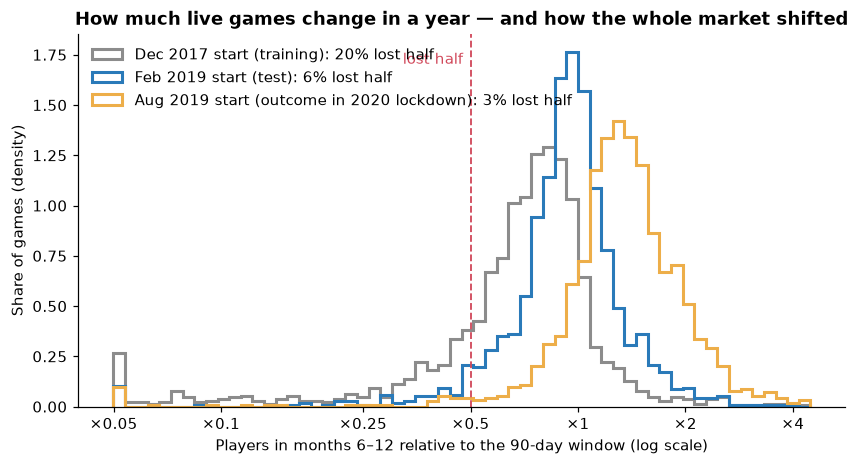

In [4]:
overview = pd.DataFrame({
    name: {"origin": ORIGINS[name].date(), "live_games": len(d), "decline_rate": d["declined"].mean(),
           "median_change": d["change_ratio"].median(), "lost_25pct_or_more": d["change_ratio"].lt(0.75).mean()}
    for name, d in datasets.items()
}).T
display(overview)

fig, ax = plt.subplots(figsize=(9, 4.4))
bins = np.linspace(-3, 1.5, 61)
for name, color, label in [("train", COLORS["neutral"], "Dec 2017 start (training)"), ("test", COLORS["stable"], "Feb 2019 start (test)"),
                           ("test_covid", COLORS["accent"], "Aug 2019 start (outcome in 2020 lockdown)")]:
    ax.hist(np.log(datasets[name]["change_ratio"].clip(lower=np.exp(-3))), bins=bins, histtype="step", lw=2, color=color,
            density=True, label=f"{label}: {datasets[name]['declined'].mean():.0%} lost half")
ax.axvline(np.log(DECLINE_RATIO), color=COLORS["decline"], ls="--", lw=1.2)
ax.text(np.log(DECLINE_RATIO) - 0.05, ax.get_ylim()[1] * 0.92, "lost half", color=COLORS["decline"], ha="right")
ticks = [0.05, 0.1, 0.25, 0.5, 1, 2, 4]
ax.set_xticks(np.log(ticks), [f"×{t:g}" for t in ticks])
ax.set(xlabel="Players in months 6–12 relative to the 90-day window (log scale)", ylabel="Share of games (density)",
       title="How much live games change in a year — and how the whole market shifted")
ax.legend(frameon=False, loc="upper left")
save(fig, "fig01_change_distribution")
plt.show()

Two facts shape the whole analysis:

1. **Most live games are stable or slowly fading**: the median game keeps most of its players. A loss of half or more is a minority event (roughly 3–20% depending on the period).
2. **The base rate moves with the market.** Starting from Dec 2017, after the 2017 boom, about one game in five lost half its players. From Feb 2019 it was about one in eighteen, and over the 2020 lockdown almost none did. A model trained in one period will therefore over- or under-estimate the *level* of risk in another. What can transfer is the *ranking*: which games are more at risk than others in the same period. The product is built on the ranking (a watch list), and the evaluation measures ranking quality (ROC-AUC, precision of the top 10%).

## 3. Exploration: who declines? (Dec 2017 start)

group  games  decline_rate  ci_low  ci_high
dimension                                                                               
Size now                 0          10–100 players    800         0.286   0.256    0.319
                         1       100–1,000 players    738         0.126   0.104    0.152
                         2          1,000+ players    220         0.114   0.078    0.162
90-day trend             0            Falling fast    799         0.282   0.252    0.314
                         1          Falling slowly    454         0.077   0.056    0.105
                         2                    Flat    177         0.073   0.043    0.122
                         3                 Growing    328         0.226   0.184    0.274
Game age                 0              < 6 months    306         0.337   0.286    0.391
                         1      6 months – 2 years    546         0.288   0.251    0.327
                         2               2–5 years    543         0.120   0.095    0.150
                         3                5+ years    344         0.049   0.031    0.078
Business model           0            Free to play    339         0.195   0.156    0.240
                         1                    Paid   1412         0.196   0.176    0.218
Genre (several per game) 11                 Racing     61         0.098   0.046    0.198
                         3                Strategy    520         0.133   0.106    0.165
                         4                     Rpg    453         0.150   0.120    0.186
                         5              Simulation    426         0.150   0.119    0.187
                         9                  Sports     85         0.153   0.092    0.244
                         10           Early Access     82         0.171   0.105    0.266
                         8   Massively Multiplayer    187         0.176   0.129    0.237
                         7            Free To Play    282         0.191   0.150    0.241
                         0                  Action    837         0.216   0.190    0.245
                         2               Adventure    517         0.246   0.211    0.285
                         1                   Indie    747         0.285   0.254    0.319
                         6                  Casual    266         0.353   0.298    0.413

Saved reports/figures/decline/fig02_decline_by_group.png


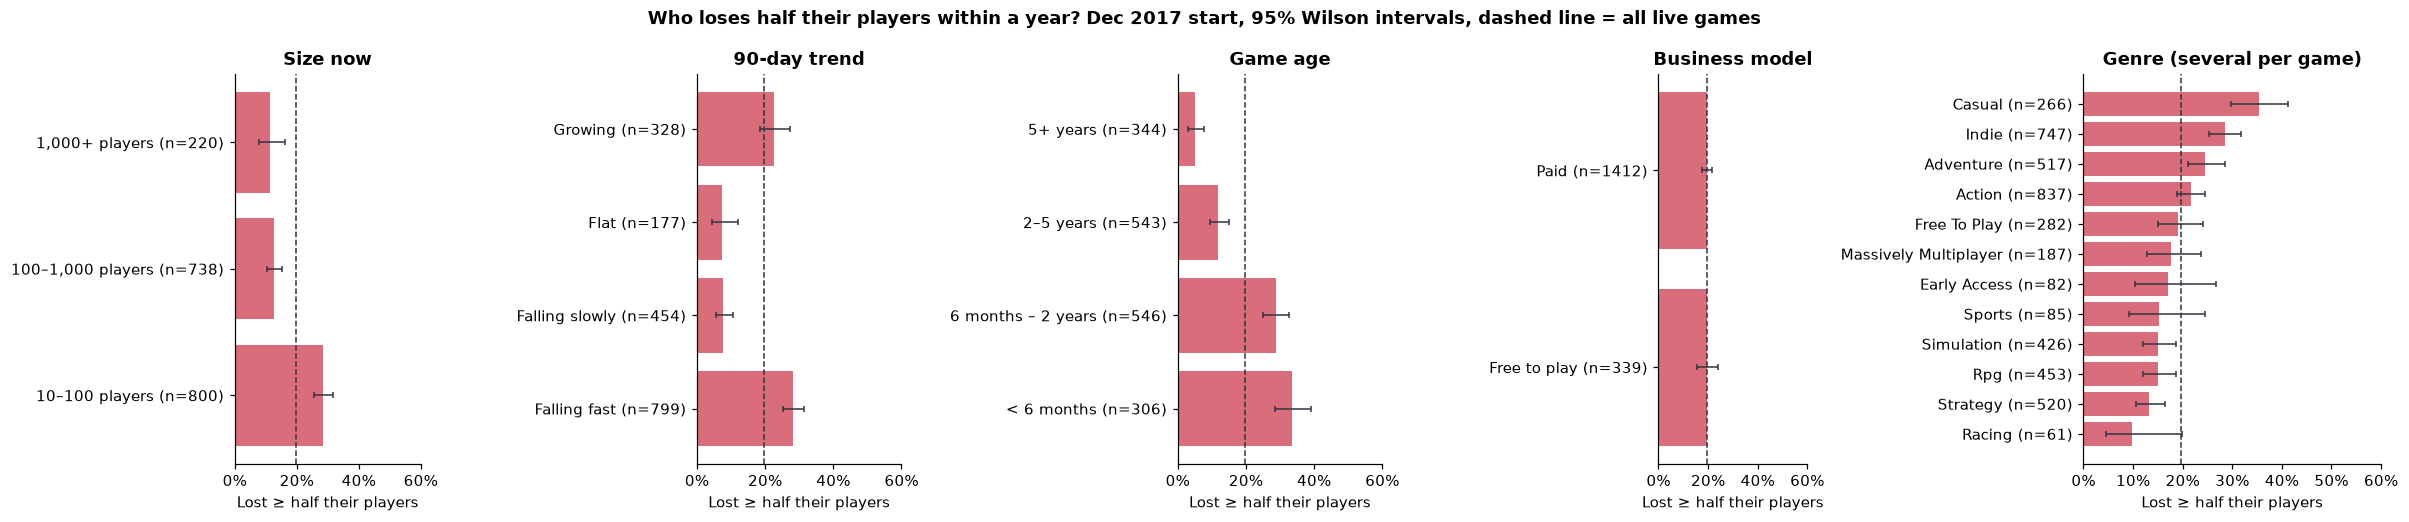

In [5]:
def wilson(successes, n, z=1.96):
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def rate_table(frame, masks):
    rows = []
    for label, mask in masks.items():
        n, k = int(mask.sum()), int(frame.loc[mask, "declined"].sum())
        low, high = wilson(k, n)
        rows.append({"group": label, "games": n, "decline_rate": k / n, "ci_low": low, "ci_high": high})
    return pd.DataFrame(rows)


age_bands = pd.cut(train["age_years"], [-0.01, 0.5, 2, 5, np.inf], labels=["< 6 months", "6 months – 2 years", "2–5 years", "5+ years"])
trend_bands = pd.cut(train["trend_log_per_30d"], [-np.inf, -0.1, -0.02, 0.02, np.inf],
                     labels=["Falling fast", "Falling slowly", "Flat", "Growing"])
groups = {
    "Size now": rate_table(train, {label: train["size_band"].eq(label) for label in SIZE_LABELS}),
    "90-day trend": rate_table(train, {label: trend_bands.eq(label) for label in trend_bands.cat.categories}),
    "Game age": rate_table(train, {label: age_bands.eq(label) for label in age_bands.cat.categories}),
    "Business model": rate_table(train, {"Free to play": train["freetoplay"].eq(1), "Paid": train["freetoplay"].eq(0)}),
    "Genre (several per game)": rate_table(train, {c.replace("genre_", "").replace("_", " ").title(): train[c].eq(1)
                                                   for c in GENRE_COLUMNS if train[c].sum() >= 30}).sort_values("decline_rate"),
}
display(pd.concat(groups, names=["dimension"]).round(3))

fig, axes = plt.subplots(1, 5, figsize=(22, 4.8), gridspec_kw={"width_ratios": [1, 1.1, 1.1, 0.8, 1.6]})
for ax, (title, table) in zip(axes, groups.items()):
    y = np.arange(len(table))
    ax.barh(y, table["decline_rate"], color=COLORS["decline"], alpha=0.8)
    ax.errorbar(table["decline_rate"], y, xerr=[table["decline_rate"] - table["ci_low"], table["ci_high"] - table["decline_rate"]],
                fmt="none", ecolor=COLORS["dark"], lw=1, capsize=2)
    ax.set_yticks(y, [f"{g} (n={n})" for g, n in zip(table["group"], table["games"])])
    ax.axvline(train["declined"].mean(), color=COLORS["dark"], ls="--", lw=1)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, max(0.6, table["ci_high"].max() * 1.05))
    ax.set_title(title)
    ax.set_xlabel("Lost ≥ half their players")
fig.suptitle("Who loses half their players within a year? Dec 2017 start, 95% Wilson intervals, dashed line = all live games",
             fontweight="bold")
fig.tight_layout()
save(fig, "fig02_decline_by_group")
plt.show()

- **Size matters, but big games are far from immune.** 29% of 10–100-player games lost half, against 11% of games with 1,000+ players.
- **Age is a strong signal.** 34% of games under six months old lost half, against 5% of games over five years old.
- **Trend cuts both ways.** Games already falling fast often keep falling (28%), but so do games that are *growing* (23%): a spike from a sale, an update or a giveaway usually fades. That is why a simple "extend the trend" rule fails, and why stability features (volatility, peak-to-mean) matter.
- **Free-to-play makes no difference here** (20% vs 20%), unlike for the floor model. Casual and Indie games decline most often (35%, 29%).

## 4. Models vs baselines

| Name | Score (higher = more likely to decline) | Flags a decline when |
|---|---|---|
| No change (persistence) | constant | never; "next year looks like today" |
| Trend rule | minus the 90-day trend | the trend, extended to the target window, loses half |
| Age rule | minus the game's age | the game is less than one year old |
| Logistic regression / random forest / gradient boosting | model probability | probability ≥ 0.5 (balanced class weights) |

Metrics, all for the **decline** class:

- **ROC-AUC** — ranking quality;
- **precision of the top 10% (watch list)**, and its **lift**, i.e. how many times the base rate that is;
- **recall of the top 10%** — share of all declines on the watch list;
- **balanced accuracy** at each method's own cut-off (sensitive to the period's base rate).

Validation: 5-fold CV grouped by publisher on the Dec 2017 start, then the **out-of-time test**: fit on Dec 2017, predict games from their Feb–Apr 2019 activity, outcome Aug 2019 – Jan 2020.

In [6]:
TREND_CUTOFF = np.log(DECLINE_RATIO) / HORIZON_MONTHS  # log-change per 30 days that would reach "half" by the target window
print(f"Trend rule: flag when the 90-day trend is below {TREND_CUTOFF:.3f} log-players per 30 days "
      f"(≈ {1 - np.exp(TREND_CUTOFF):.0%} lost per month, projected over {HORIZON_MONTHS:.1f} months)")

BASELINES = ["No change (persistence)", "Trend rule", "Age rule"]
ML_MODELS = ["Logistic regression", "Random forest", "Gradient boosting"]
CANDIDATES = BASELINES + ML_MODELS


def make_model(kind):
    imputer = ("impute", SimpleImputer(strategy="median"))
    if kind == "Logistic regression":
        return Pipeline([imputer, ("scale", StandardScaler()), ("model", LogisticRegression(C=0.3, max_iter=5000, class_weight="balanced"))])
    if kind == "Random forest":
        return Pipeline([imputer, ("model", RandomForestClassifier(
            n_estimators=500, min_samples_leaf=3, max_features="sqrt", class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE))])
    if kind == "Gradient boosting":
        return Pipeline([imputer, ("model", HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=300, max_leaf_nodes=15, l2_regularization=1.0,
            class_weight="balanced", random_state=RANDOM_STATE))])
    raise ValueError(kind)


def scores_for(name, fitted, frame, features=ALL_FEATURES):
    if name == "No change (persistence)":
        return np.zeros(len(frame))
    if name == "Trend rule":
        return -frame["trend_log_per_30d"].fillna(0).to_numpy()
    if name == "Age rule":
        return -frame["age_years"].fillna(frame["age_years"].median()).to_numpy()
    return fitted.predict_proba(frame[features])[:, 1]


def labels_for(name, scores):
    if name == "No change (persistence)":
        return np.zeros(len(scores), dtype=int)
    if name == "Trend rule":
        return (scores > -TREND_CUTOFF).astype(int)
    if name == "Age rule":
        return (scores > -1).astype(int)
    return (scores >= 0.5).astype(int)


def top_share(y, scores, share=WATCHLIST_SHARE):
    k = max(1, int(np.ceil(share * len(y))))
    order = np.argsort(-scores, kind="stable")[:k]
    return y[order].mean(), y[order].sum() / max(1, y.sum())


def metrics(y, scores, predicted):
    constant = len(np.unique(scores)) == 1
    watch_precision, watch_recall = (y.mean(), WATCHLIST_SHARE) if constant else top_share(y, scores)
    return {
        "roc_auc": 0.5 if constant else roc_auc_score(y, scores),
        "avg_precision": y.mean() if constant else average_precision_score(y, scores),
        "watchlist_precision": watch_precision,
        "watchlist_lift": watch_precision / y.mean(),
        "watchlist_recall": watch_recall,
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "precision": precision_score(y, predicted, zero_division=0),
        "recall": recall_score(y, predicted, zero_division=0),
    }


def bootstrap_ci(y, scores, predicted, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    draws = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() != y[idx].max():
            draws.append(metrics(y[idx], scores[idx], predicted[idx]))
    draws = pd.DataFrame(draws)
    return draws.quantile(0.025), draws.quantile(0.975)


cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_train = train["declined"].to_numpy()
oof_scores = {name: np.zeros(len(train)) for name in CANDIDATES}
cv_rows = []
for fold, (fit_idx, val_idx) in enumerate(cv.split(train, y_train, groups=train["group"])):
    fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
    for name in CANDIDATES:
        fitted = make_model(name).fit(fit_part[ALL_FEATURES], fit_part["declined"]) if name in ML_MODELS else None
        scores = scores_for(name, fitted, val_part)
        oof_scores[name][val_idx] = scores
        cv_rows.append({"model": name, "fold": fold, **metrics(val_part["declined"].to_numpy(), scores, labels_for(name, scores))})
cv_results = pd.DataFrame(cv_rows).drop(columns="fold").groupby("model", sort=False).agg(["mean", "std"])
display(cv_results[["roc_auc", "watchlist_precision", "watchlist_lift", "balanced_accuracy"]].round(3))

Trend rule: flag when the 90-day trend is below -0.093 log-players per 30 days (≈ 9% lost per month, projected over 7.5 months)


roc_auc        watchlist_precision        watchlist_lift        balanced_accuracy       
                           mean    std                mean    std           mean    std              mean    std
model                                                                                                           
No change (persistence)   0.500  0.000               0.197  0.001          1.000  0.000             0.500  0.000
Trend rule                0.652  0.091               0.667  0.171          3.379  0.875             0.613  0.053
Age rule                  0.693  0.044               0.372  0.061          1.885  0.303             0.599  0.042
Logistic regression       0.883  0.049               0.839  0.060          4.249  0.287             0.782  0.051
Random forest             0.889  0.031               0.839  0.089          4.250  0.441             0.779  0.041
Gradient boosting         0.874  0.027               0.844  0.064          4.277  0.310             0.782  0.041

In [7]:
best_name = cv_results.loc[ML_MODELS, ("roc_auc", "mean")].idxmax()  # chosen on CV, never on the test set
fitted_models = {name: make_model(name).fit(train[ALL_FEATURES], y_train) for name in ML_MODELS}
best_model = fitted_models[best_name]
y_test = test["declined"].to_numpy()
test_scores, test_rows = {}, []
for name in CANDIDATES:
    scores = scores_for(name, fitted_models.get(name), test)
    predicted = labels_for(name, scores)
    test_scores[name] = scores
    low, high = bootstrap_ci(y_test, scores, predicted)
    test_rows.append({"model": name, **metrics(y_test, scores, predicted),
                      **{f"{m}_low": low[m] for m in ["roc_auc", "watchlist_precision"]},
                      **{f"{m}_high": high[m] for m in ["roc_auc", "watchlist_precision"]}})
test_results = pd.DataFrame(test_rows).set_index("model")
print(f"Model chosen by grouped CV: {best_name}")
print(f"Out-of-time test: {len(test):,} live games, {y_test.sum()} lost half ({y_test.mean():.1%})")
display(test_results.round(3))

Model chosen by grouped CV: Random forest
Out-of-time test: 1,559 live games, 88 lost half (5.6%)


,roc_auc,avg_precision,watchlist_precision,watchlist_lift,watchlist_recall,balanced_accuracy,precision,recall,roc_auc_low,watchlist_precision_low,roc_auc_high,watchlist_precision_high
model,,,,,,,,,,,,
No change (persistence),0.500,0.056,0.056,1.000,0.100,0.500,0.000,0.000,0.500,0.045,0.500,0.068
Trend rule,0.586,0.288,0.218,3.861,0.386,0.588,0.083,0.523,0.495,0.147,0.674,0.282
Age rule,0.611,0.093,0.077,1.363,0.136,0.529,0.140,0.091,0.559,0.038,0.665,0.128
Logistic regression,0.819,0.412,0.276,4.883,0.489,0.707,0.279,0.489,0.762,0.205,0.864,0.359
Random forest,0.826,0.385,0.282,4.997,0.500,0.687,0.409,0.409,0.774,0.212,0.871,0.359
Gradient boosting,0.817,0.347,0.282,4.997,0.500,0.675,0.333,0.398,0.765,0.205,0.864,0.359


**Reading the results.**

- Unlike the 10-player question, a relative decline **cannot be read off simple signals**: the trend rule (AUC 0.586) and the age rule (0.611) are close to chance. The random forest reaches **0.826 (95% CI 0.774–0.871)**; all three ML models are within 0.01 of each other.
- **Watch list:** the top 10% by model score held **28% games that really lost half**, 5.0× the 5.6% base rate. It contained **half of all collapses** (44 of 88). The trend rule's top 10% held 22%.
- **Thresholded labels** (balanced accuracy 0.69) look weaker, because a 0.5 cut-off learned when 20% of games declined over-flags in a year when 6% did. The product therefore ranks, not thresholds (Section 9).

Saved reports/figures/decline/fig03_model_comparison.png


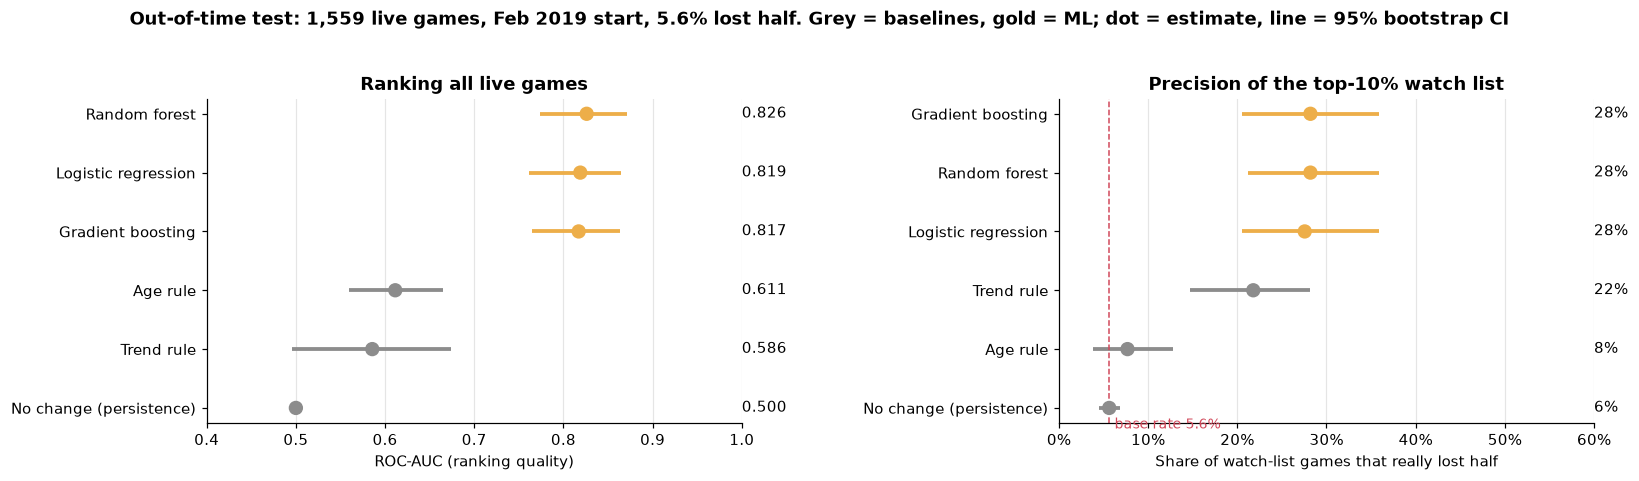

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
panels = [("roc_auc", "roc_auc_low", "roc_auc_high", (0.4, 1.0), "ROC-AUC (ranking quality)", "Ranking all live games"),
          ("watchlist_precision", "watchlist_precision_low", "watchlist_precision_high", (0, 0.6),
           "Share of watch-list games that really lost half", "Precision of the top-10% watch list")]
for ax, (column, low, high, xlim, xlabel, title) in zip(axes, panels):
    table = test_results.sort_values(column)
    y = np.arange(len(table))
    colors = [COLORS["accent"] if n in ML_MODELS else COLORS["neutral"] for n in table.index]
    ax.hlines(y, table[low], table[high], color=colors, lw=2.5)
    ax.scatter(table[column], y, color=colors, s=70, zorder=3)
    for yi, value in zip(y, table[column]):
        ax.text(1.0, yi, f"{value:.0%}" if column != "roc_auc" else f"{value:.3f}", transform=ax.get_yaxis_transform(),
                va="center", ha="left", fontsize=9.5)
    if column == "watchlist_precision":
        ax.axvline(y_test.mean(), color=COLORS["decline"], ls="--", lw=1)
        ax.text(y_test.mean() + 0.006, -0.35, f"base rate {y_test.mean():.1%}", color=COLORS["decline"], fontsize=9)
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_yticks(y, table.index)
    ax.set_xlim(*xlim)
    ax.grid(axis="x", color="#e5e5e5", lw=0.8)
    ax.set_axisbelow(True)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
fig.suptitle(f"Out-of-time test: {len(test):,} live games, Feb 2019 start, {y_test.mean():.1%} lost half. "
             "Grey = baselines, gold = ML; dot = estimate, line = 95% bootstrap CI", fontweight="bold", y=1.03)
fig.tight_layout(w_pad=5)
save(fig, "fig03_model_comparison")
plt.show()

Saved reports/figures/decline/fig04_roc_calibration.png


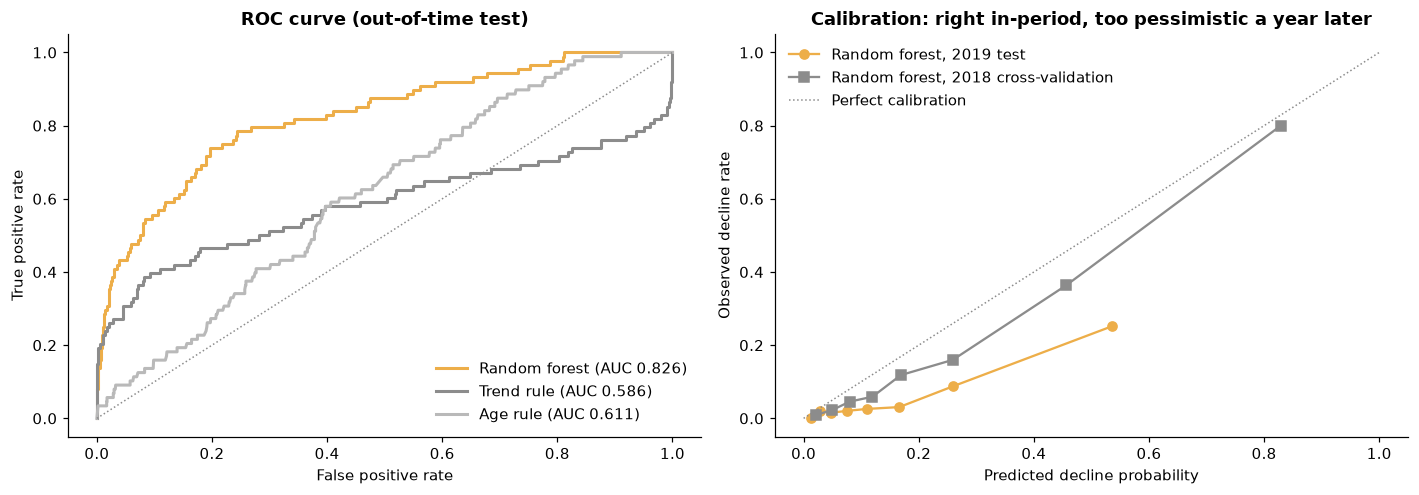

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for name, color in [(best_name, COLORS["accent"]), ("Trend rule", COLORS["neutral"]), ("Age rule", "#b9b9b9")]:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {test_results.loc[name, 'roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=COLORS["neutral"], ls=":", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (out-of-time test)")
axes[0].legend(frameon=False, loc="lower right")
prob_true, prob_pred = calibration_curve(y_test, test_scores[best_name], n_bins=8, strategy="quantile")
axes[1].plot(prob_pred, prob_true, marker="o", color=COLORS["accent"], label=f"{best_name}, 2019 test")
oof_true, oof_pred = calibration_curve(y_train, oof_scores[best_name], n_bins=8, strategy="quantile")
axes[1].plot(oof_pred, oof_true, marker="s", color=COLORS["neutral"], label=f"{best_name}, 2018 cross-validation")
axes[1].plot([0, 1], [0, 1], color=COLORS["neutral"], ls=":", lw=1, label="Perfect calibration")
axes[1].set(xlabel="Predicted decline probability", ylabel="Observed decline rate",
            title="Calibration: right in-period, too pessimistic a year later")
axes[1].legend(frameon=False)
fig.tight_layout()
save(fig, "fig04_roc_calibration")
plt.show()

## 5. Big games and launch-stage games

These are the two cases the 10-player floor model could not handle.

### 5a. By current size

,size_band,model,games,declines,roc_auc,auc_low,auc_high,watchlist_precision,base_rate
0,10–100 players,Trend rule,797,52,0.643,0.524,0.751,0.275,0.065
1,10–100 players,Age rule,797,52,0.651,0.580,0.715,0.125,0.065
2,10–100 players,Random forest,797,52,0.876,0.827,0.921,0.388,0.065
3,"100–1,000 players",Trend rule,592,25,0.518,0.379,0.667,0.117,0.042
4,"100–1,000 players",Age rule,592,25,0.548,0.448,0.649,0.033,0.042
5,"100–1,000 players",Random forest,592,25,0.748,0.634,0.844,0.167,0.042
6,"1,000+ players",Trend rule,170,11,0.469,0.204,0.743,0.176,0.065
7,"1,000+ players",Age rule,170,11,0.574,0.393,0.749,0.118,0.065
8,"1,000+ players",Random forest,170,11,0.802,0.626,0.937,0.294,0.065


Saved reports/figures/decline/fig05_by_size.png


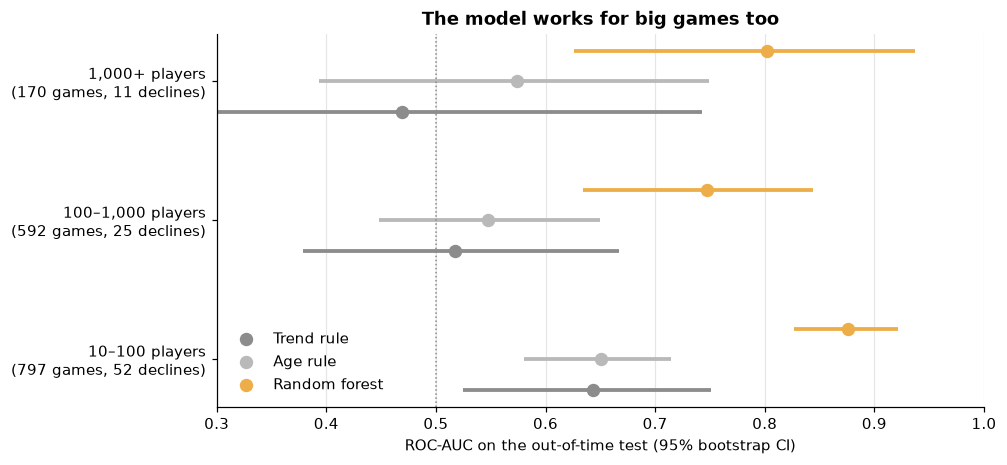

In [10]:
size_rows = []
for band in SIZE_LABELS:
    mask = (test["size_band"] == band).to_numpy()
    for name in ["Trend rule", "Age rule", best_name]:
        scores, y_band = test_scores[name][mask], y_test[mask]
        low, high = bootstrap_ci(y_band, scores, labels_for(name, scores), n_boot=500)
        size_rows.append({"size_band": band, "model": name, "games": int(mask.sum()), "declines": int(y_band.sum()),
                          "roc_auc": roc_auc_score(y_band, scores), "auc_low": low["roc_auc"], "auc_high": high["roc_auc"],
                          "watchlist_precision": top_share(y_band, scores)[0], "base_rate": y_band.mean()})
size_results = pd.DataFrame(size_rows)
display(size_results.round(3))

fig, ax = plt.subplots(figsize=(9, 4.4))
offsets = {"Trend rule": -0.22, "Age rule": 0, best_name: 0.22}
colors = {"Trend rule": COLORS["neutral"], "Age rule": "#b9b9b9", best_name: COLORS["accent"]}
for name, offset in offsets.items():
    part = size_results[size_results["model"] == name].reset_index(drop=True)
    y = np.arange(len(part)) + offset
    ax.hlines(y, part["auc_low"], part["auc_high"], color=colors[name], lw=2.5)
    ax.scatter(part["roc_auc"], y, color=colors[name], s=60, zorder=3, label=name)
part = size_results[size_results["model"] == best_name].reset_index(drop=True)
ax.set_yticks(np.arange(len(part)), [f"{b}\n({g} games, {d} declines)" for b, g, d in zip(part["size_band"], part["games"], part["declines"])])
ax.axvline(0.5, color=COLORS["neutral"], ls=":", lw=1)
ax.set_xlim(0.3, 1.0)
ax.grid(axis="x", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)
ax.set(xlabel="ROC-AUC on the out-of-time test (95% bootstrap CI)", title="The model works for big games too")
ax.legend(frameon=False, loc="lower left")
save(fig, "fig05_by_size")
plt.show()

The model ranks well **in every size band**, including games with 1,000+ players (AUC 0.80), where both rules are at chance. The big-game interval is wide (0.63–0.94), because only 11 of 170 big games lost half in this period.

### 5b. Launch-stage games

Here each game's origin is its own **launch**: the store release date, or the start of tracking for games released at most 45 days before it. That gives two kinds of launch:

- games released shortly before tracking began;
- Early Access games whose full (1.0) release happened during tracking.

For these rows the 90-day feature window *is* the launch period, and the question is exactly "is our new game going to hold its players?". The model is the one trained on the Dec 2017 catalogue with these games removed from training, so nothing about them leaks in.

Launch-stage games with ≥10 players: 141 ({'Released ≤45 days before tracking': 74, '1.0 release during tracking': 67}); 51% lost half


,roc_auc,auc_low,auc_high,avg_precision,balanced_accuracy,precision,recall
model,,,,,,,
Trend rule,0.774,0.690,0.848,0.778,0.661,0.613,0.944
Random forest,0.787,0.704,0.866,0.770,0.684,0.787,0.514


Saved reports/figures/decline/fig06_launch_stage.png


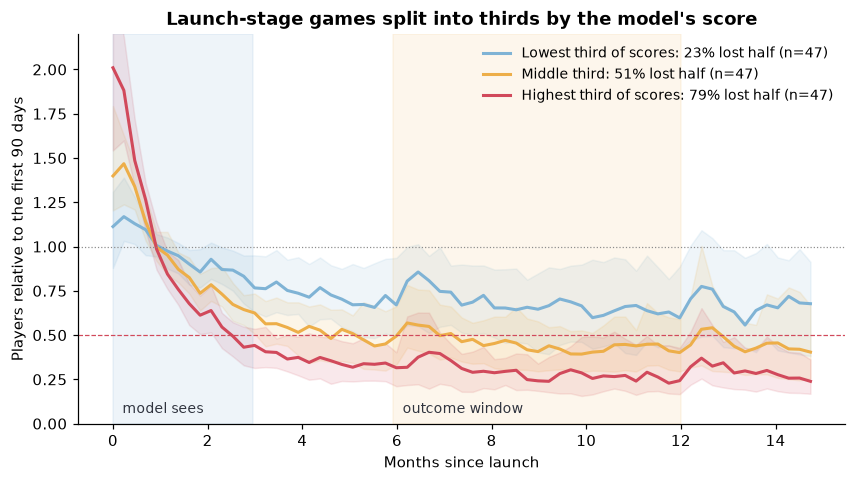

In [11]:
lag = (static["releasedate"] - DATA_START).dt.days
launch_origin = static["releasedate"].where(lag > 0, DATA_START)
launch_origin = launch_origin[(lag >= -45) & (static["releasedate"] + pd.Timedelta(days=TARGET_END) <= DATA_END)]
launch = build_dataset(launch_origin)
launch["launch_kind"] = np.where(launch["origin"] > DATA_START, "1.0 release during tracking", "Released ≤45 days before tracking")
print(f"Launch-stage games with ≥{MIN_PLAYERS} players: {len(launch)} "
      f"({launch['launch_kind'].value_counts().to_dict()}); {launch['declined'].mean():.0%} lost half")

mature_train = train[~train.index.isin(launch.index)]
launch_models = {name: make_model(name).fit(mature_train[ALL_FEATURES], mature_train["declined"]) for name in ML_MODELS}
y_launch = launch["declined"].to_numpy()
launch_rows = []
for name in ["Trend rule", best_name]:
    scores = scores_for(name, launch_models.get(name), launch)
    low, high = bootstrap_ci(y_launch, scores, labels_for(name, scores), n_boot=500)
    launch_rows.append({"model": name, **metrics(y_launch, scores, labels_for(name, scores)),
                        "auc_low": low["roc_auc"], "auc_high": high["roc_auc"]})
launch_results = pd.DataFrame(launch_rows).set_index("model")
launch_scores = scores_for(best_name, launch_models[best_name], launch)
display(launch_results[["roc_auc", "auc_low", "auc_high", "avg_precision", "balanced_accuracy", "precision", "recall"]].round(3))


def relative_curve(frame, horizon=450):
    rows = with_offset(panel[panel["appid"].isin(frame.index)][["appid", "date", "mean_player_count"]], frame["origin"])
    rows = rows[rows["t"].between(0, horizon)]
    base = rows[rows["t"] < FEATURE_DAYS].groupby("appid")["mean_player_count"].mean()
    rows["relative"] = rows["mean_player_count"] / rows["appid"].map(base)
    weekly = rows.assign(week=rows["t"] // 7).groupby(["week", "appid"])["relative"].mean().groupby("week")
    return weekly.median(), weekly.quantile(0.25), weekly.quantile(0.75)


launch_risk = pd.qcut(launch_scores, 3, labels=["Lowest third of scores", "Middle third", "Highest third of scores"])
fig, ax = plt.subplots(figsize=(9, 4.6))
for label, color in zip(launch_risk.categories, ["#7fb3d5", COLORS["accent"], COLORS["decline"]]):
    subset = launch[launch_risk == label]
    median, q1, q3 = relative_curve(subset)
    ax.plot(median.index * 7 / 30.4, median, color=color, lw=2,
            label=f"{label}: {subset['declined'].mean():.0%} lost half (n={len(subset)})")
    ax.fill_between(median.index * 7 / 30.4, q1, q3, color=color, alpha=0.12)
ax.axhline(1, color=COLORS["neutral"], lw=0.8, ls=":")
ax.axhline(DECLINE_RATIO, color=COLORS["decline"], lw=0.8, ls="--")
ax.axvspan(0, FEATURE_DAYS / 30.4, color=COLORS["stable"], alpha=0.08)
ax.axvspan(TARGET_START / 30.4, TARGET_END / 30.4, color=COLORS["accent"], alpha=0.10)
ax.text(0.2, 0.06, "model sees", fontsize=9, color=COLORS["dark"])
ax.text(TARGET_START / 30.4 + 0.2, 0.06, "outcome window", fontsize=9, color=COLORS["dark"])
ax.set(xlabel="Months since launch", ylabel="Players relative to the first 90 days", ylim=(0, 2.2),
       title="Launch-stage games split into thirds by the model's score")
ax.legend(frameon=False, loc="upper right", fontsize=9)
save(fig, "fig06_launch_stage")
plt.show()

**Launch stage: useful, but not better than a simple rule.** Half the launch-stage games (51%) lost half their players by months 6–12.

- The model ranks them well (AUC 0.787, 95% CI 0.704–0.866). Its highest-scored third lost half 79% of the time, against 23% for its lowest third.
- The plain trend rule does about as well here (AUC 0.774). Right after launch the decline is already visible in the first 90 days, so the trend alone carries most of the signal.
- The model's advantage on launches is precision: when it flags a launch, it is right 79% of the time, against 61% for the trend rule. It flags fewer of them.

With 141 launches, a launch-specific model trained on launch data is the obvious next step.

## 6. Does Twitch help? Ablation and importance

In [12]:
ABLATION_SETS = {
    "Metadata only": META_FEATURES, "Twitch only": TWITCH_FEATURES, "Metadata + Twitch": META_FEATURES + TWITCH_FEATURES,
    "Steam only": STEAM_FEATURES, "Metadata + Steam": META_FEATURES + STEAM_FEATURES, "Metadata + Steam + Twitch": ALL_FEATURES,
}
ablation_rows, ablation_scores = [], {}
for set_name, columns in ABLATION_SETS.items():
    cv_auc = [roc_auc_score(y_train[v], clone(make_model(best_name)).fit(train.iloc[f][columns], y_train[f])
                            .predict_proba(train.iloc[v][columns])[:, 1])
              for f, v in cv.split(train, y_train, groups=train["group"])]
    scores = clone(make_model(best_name)).fit(train[columns], y_train).predict_proba(test[columns])[:, 1]
    ablation_scores[set_name] = scores
    low, high = bootstrap_ci(y_test, scores, (scores >= 0.5).astype(int), n_boot=500)
    ablation_rows.append({"feature_set": set_name, "n_features": len(columns), "cv_auc_mean": np.mean(cv_auc), "cv_auc_std": np.std(cv_auc),
                          "test_auc": roc_auc_score(y_test, scores), "test_auc_low": low["roc_auc"], "test_auc_high": high["roc_auc"],
                          "test_watchlist_precision": top_share(y_test, scores)[0]})
ablation = pd.DataFrame(ablation_rows).set_index("feature_set")
display(ablation.round(3))

rng = np.random.default_rng(RANDOM_STATE)
with_twitch, without_twitch = ablation_scores["Metadata + Steam + Twitch"], ablation_scores["Metadata + Steam"]
deltas = []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test[idx].min() != y_test[idx].max():
        deltas.append(roc_auc_score(y_test[idx], with_twitch[idx]) - roc_auc_score(y_test[idx], without_twitch[idx]))
twitch_delta = (roc_auc_score(y_test, with_twitch) - roc_auc_score(y_test, without_twitch), *np.quantile(deltas, [0.025, 0.975]))
print(f"AUC change from adding Twitch to Metadata + Steam: {twitch_delta[0]:+.4f} (95% CI {twitch_delta[1]:+.4f} to {twitch_delta[2]:+.4f})")

,n_features,cv_auc_mean,cv_auc_std,test_auc,test_auc_low,test_auc_high,test_watchlist_precision
feature_set,,,,,,,
Metadata only,42,0.800,0.069,0.655,0.597,0.719,0.109
Twitch only,7,0.664,0.054,0.587,0.526,0.657,0.115
Metadata + Twitch,49,0.808,0.068,0.678,0.620,0.737,0.141
Steam only,8,0.863,0.029,0.824,0.766,0.868,0.295
Metadata + Steam,50,0.892,0.028,0.827,0.773,0.870,0.282
Metadata + Steam + Twitch,57,0.889,0.028,0.826,0.774,0.871,0.282


AUC change from adding Twitch to Metadata + Steam: -0.0006 (95% CI -0.0090 to +0.0077)


,auc_drop,std
group,,
Metadata,0.0292,0.0118
Steam activity,0.2457,0.0181
Twitch,0.0019,0.0042
Genres + tags,0.0070,0.0071


,auc_drop,std
feature,,
volatility,0.0353,0.0049
trend_log_per_30d,0.0129,0.0069
last_vs_first_month,0.0121,0.0063
age_years,0.0110,0.0019
log_peak_to_mean,0.0084,0.0052
freetoplay,0.0047,0.0033
log_early_min,0.0039,0.0060
tag_free_to_play,0.0025,0.0015
n_tags,0.0024,0.0022


Saved reports/figures/decline/fig07_ablation_importance.png


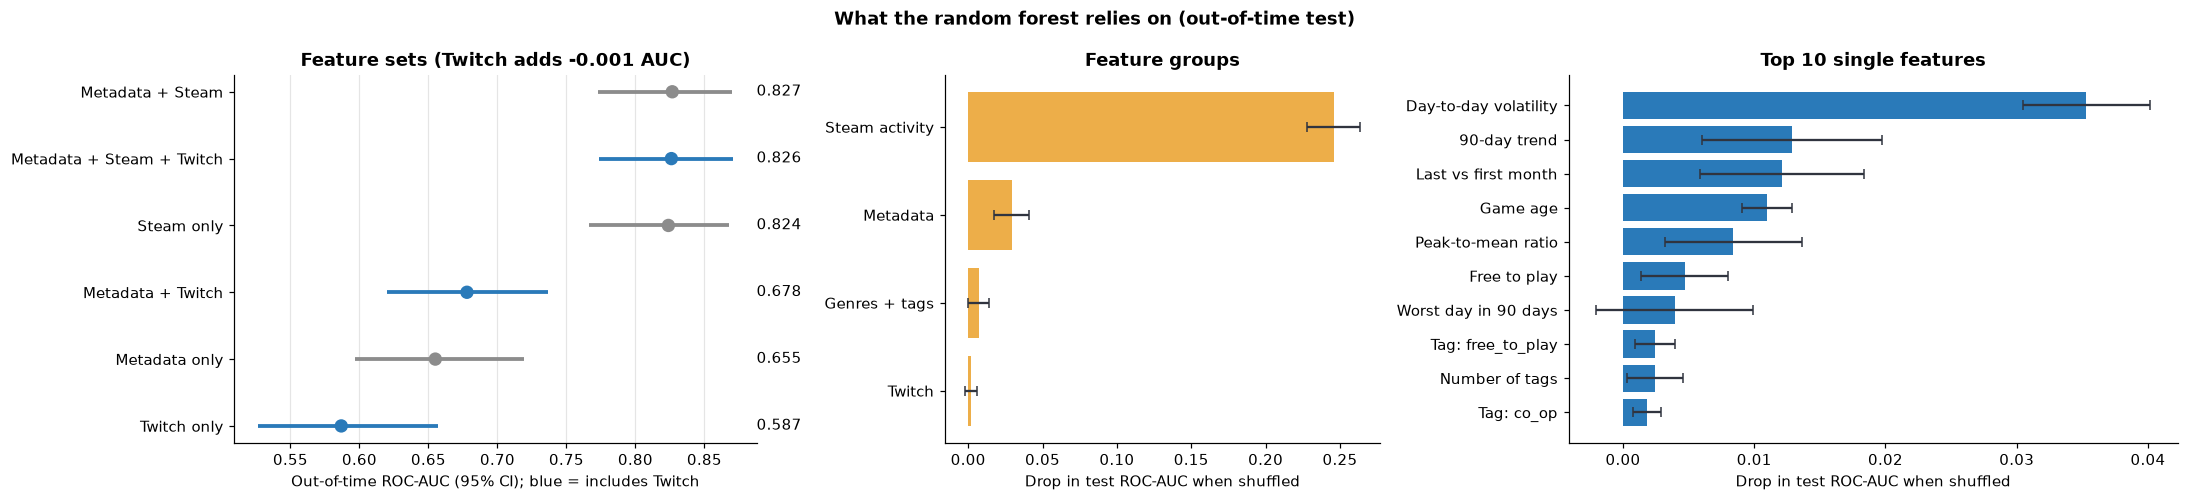

In [13]:
def permutation_auc_drop(model, frame, y, columns_to_shuffle, n_repeats=20, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(frame[ALL_FEATURES])[:, 1])
    drops = []
    for _ in range(n_repeats):
        shuffled = frame[ALL_FEATURES].copy()
        shuffled[columns_to_shuffle] = shuffled[columns_to_shuffle].to_numpy()[rng.permutation(len(frame))]
        drops.append(base - roc_auc_score(y, model.predict_proba(shuffled)[:, 1]))
    return np.mean(drops), np.std(drops)


group_importance = pd.DataFrame([(g, *permutation_auc_drop(best_model, test, y_test, cols)) for g, cols in
                                 {**FEATURE_GROUPS, "Genres + tags": GENRE_COLUMNS + TAG_COLUMNS}.items()],
                                columns=["group", "auc_drop", "std"]).set_index("group")
single_importance = pd.DataFrame([(f, *permutation_auc_drop(best_model, test, y_test, [f], n_repeats=10)) for f in ALL_FEATURES],
                                 columns=["feature", "auc_drop", "std"]).set_index("feature").sort_values("auc_drop", ascending=False)
display(group_importance.round(4))
display(single_importance.head(12).round(4))

FEATURE_LABELS = {
    "log_early_mean": "Players now (90-day mean)", "log_early_min": "Worst day in 90 days", "low_day_share": "Share of near-empty days",
    "trend_log_per_30d": "90-day trend", "last_vs_first_month": "Last vs first month", "volatility": "Day-to-day volatility",
    "log_peak_to_mean": "Peak-to-mean ratio", "weekend_uplift": "Weekend uplift", "age_years": "Game age",
    "log_twitch_avg_viewers": "Twitch avg viewers", "log_twitch_view_minutes": "Twitch watch time",
    "twitch_viewers_per_player": "Twitch viewers per player", "log_twitch_peak_viewers": "Twitch peak viewers",
    "n_languages": "Supported languages", "n_packages": "Store packages", "log_publisher_catalog": "Publisher catalogue size",
    "n_tags": "Number of tags", "freetoplay": "Free to play", "log_twitch_avg_channels": "Twitch channels",
    "twitch_mapped": "Has a Twitch category", "twitch_months_in_top": "Months in Twitch top 2,000", "early_access": "Still in Early Access",
    "n_developers": "Number of developers", "release_unknown": "Release date unknown",
}
fig, axes = plt.subplots(1, 3, figsize=(20, 4.6), gridspec_kw={"width_ratios": [1.2, 1, 1.4]})
order = ablation.sort_values("test_auc").index
y = np.arange(len(order))
colors = [COLORS["stable"] if "Twitch" in n else COLORS["neutral"] for n in order]
axes[0].hlines(y, ablation.loc[order, "test_auc_low"], ablation.loc[order, "test_auc_high"], color=colors, lw=2.5)
axes[0].scatter(ablation.loc[order, "test_auc"], y, color=colors, s=60, zorder=3)
for yi, value in zip(y, ablation.loc[order, "test_auc"]):
    axes[0].text(1.0, yi, f"{value:.3f}", transform=axes[0].get_yaxis_transform(), va="center", fontsize=9.5)
axes[0].set_yticks(y, order)
axes[0].set(xlabel="Out-of-time ROC-AUC (95% CI); blue = includes Twitch",
            title=f"Feature sets (Twitch adds {twitch_delta[0]:+.3f} AUC)")
axes[0].grid(axis="x", color="#e5e5e5", lw=0.8)
g = group_importance.sort_values("auc_drop")
axes[1].barh(g.index, g["auc_drop"], xerr=g["std"], color=COLORS["accent"], ecolor=COLORS["dark"], capsize=3)
axes[1].set(xlabel="Drop in test ROC-AUC when shuffled", title="Feature groups")
s = single_importance.head(10).iloc[::-1]
axes[2].barh([FEATURE_LABELS.get(f, f.replace("genre_", "Genre: ").replace("tag_", "Tag: ")) for f in s.index], s["auc_drop"],
             xerr=s["std"], color=COLORS["stable"], ecolor=COLORS["dark"], capsize=3)
axes[2].set(xlabel="Drop in test ROC-AUC when shuffled", title="Top 10 single features")
fig.suptitle(f"What the {best_name.lower()} relies on (out-of-time test)", fontweight="bold")
fig.tight_layout()
save(fig, "fig07_ablation_importance")
plt.show()

**Twitch adds nothing here either** (−0.0006 AUC, 95% CI −0.009 to +0.008). Steam activity carries almost all the signal. Its key parts are **volatility** (spiky games fade), the **trend**, the change from the first to the last month, and the **game's age**. Metadata adds a little in CV (0.863 → 0.892) but not in the out-of-time test.

## 7. Robustness

### 7a. How big a decline?

In [14]:
sensitivity_rows = []
for ratio, label in [(0.75, "lost ≥ 25%"), (0.5, "lost ≥ 50%"), (0.25, "lost ≥ 75%")]:
    y_fit = train["change_ratio"].lt(ratio).astype(int).to_numpy()
    y_eval = test["change_ratio"].lt(ratio).astype(int).to_numpy()
    model = clone(make_model(best_name)).fit(train[ALL_FEATURES], y_fit)
    m_scores, t_scores = model.predict_proba(test[ALL_FEATURES])[:, 1], test_scores["Trend rule"]
    sensitivity_rows.append({"definition": label, "test_rate": y_eval.mean(), "test_events": int(y_eval.sum()),
                             "trend_rule_auc": roc_auc_score(y_eval, t_scores), "model_auc": roc_auc_score(y_eval, m_scores),
                             "trend_rule_watchlist_precision": top_share(y_eval, t_scores)[0],
                             "model_watchlist_precision": top_share(y_eval, m_scores)[0]})
sensitivity = pd.DataFrame(sensitivity_rows).set_index("definition")
display(sensitivity.round(3))

,test_rate,test_events,trend_rule_auc,model_auc,trend_rule_watchlist_precision,model_watchlist_precision
definition,,,,,,
lost ≥ 25%,0.192,300,0.510,0.747,0.429,0.526
lost ≥ 50%,0.056,88,0.586,0.826,0.218,0.282
lost ≥ 75%,0.015,24,0.762,0.958,0.096,0.122


For every definition of "decline" (losing 25%, 50% or 75%), the model beats the trend rule by a wide margin.

### 7b. The 2020 lockdown period

Train on the Dec 2017 and Jun 2018 starts, predict from Aug–Oct 2019 activity, with the outcome in Jan–Jul 2020, when lockdowns lifted almost every game.

In [15]:
covid = datasets["test_covid"]
train_both = pd.concat([datasets["train"], datasets["train_2"]])
y_covid = covid["declined"].to_numpy()
covid_model = clone(make_model(best_name)).fit(train_both[ALL_FEATURES], train_both["declined"])
covid_rows = []
for name in ["Trend rule", "Age rule", best_name]:
    scores = scores_for(name, covid_model if name == best_name else None, covid)
    low, high = bootstrap_ci(y_covid, scores, labels_for(name, scores), n_boot=500)
    covid_rows.append({"model": name, **metrics(y_covid, scores, labels_for(name, scores)), "auc_low": low["roc_auc"], "auc_high": high["roc_auc"]})
covid_results = pd.DataFrame(covid_rows).set_index("model")
print(f"Lockdown test: {len(covid):,} live games, {y_covid.sum()} lost half ({y_covid.mean():.1%})")
display(covid_results[["roc_auc", "auc_low", "auc_high", "watchlist_precision", "watchlist_lift", "watchlist_recall"]].round(3))

Lockdown test: 1,528 live games, 39 lost half (2.6%)


,roc_auc,auc_low,auc_high,watchlist_precision,watchlist_lift,watchlist_recall
model,,,,,,
Trend rule,0.562,0.444,0.676,0.072,2.817,0.282
Age rule,0.640,0.566,0.704,0.033,1.280,0.128
Random forest,0.826,0.748,0.896,0.150,5.890,0.590


Even in the lockdown year, when only 2.6% of live games lost half, the model's ranking held (AUC 0.826). Its watch list caught 59% of the collapses at 5.9× the base rate. The ranking transfers across very different market periods.

## 8. How large will the change be? (regression)

Target: log of (future players + 1) / (current players + 1). Baselines: "no change" (0) and the 90-day trend extended over the horizon.

In [16]:
regressor = Pipeline([("impute", SimpleImputer(strategy="median")), ("model", RandomForestRegressor(
    n_estimators=500, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE))])
regressor.fit(train[ALL_FEATURES], train["log_change"])
truth = test["log_change"].to_numpy()
predictions = {
    "No change (persistence)": np.zeros(len(test)),
    "Trend extrapolation": test["trend_log_per_30d"].fillna(0).to_numpy() * HORIZON_MONTHS,
    "Random forest": regressor.predict(test[ALL_FEATURES]),
}
regression_rows = []
for name, pred in predictions.items():
    regression_rows.append({
        "model": name, "MAE_log": np.mean(np.abs(pred - truth)),
        "median_abs_error_pct_points": np.median(np.abs(np.exp(pred) - np.exp(truth))) * 100,
        "rank_corr_with_actual_change": pd.Series(pred).corr(pd.Series(truth), method="spearman") if pred.std() > 0 else np.nan,
    })
regression_results = pd.DataFrame(regression_rows).set_index("model")
display(regression_results.round(3))

,MAE_log,median_abs_error_pct_points,rank_corr_with_actual_change
model,,,
No change (persistence),0.274,16.512,NaN
Trend extrapolation,0.894,46.873,0.014
Random forest,0.295,17.676,0.339


**Predicting the exact size of the change does not beat "no change"** (MAE 0.274 vs 0.295 in log units). The forest's predictions do rank games by their actual change (Spearman 0.34; trend extrapolation 0.01), which is the same finding as the classifier: **the value is in who to worry about, not in a precise forecast.**

## 9. Deliverable: a ranked watch list

The product ranks the whole catalogue by decline risk and splits it into three tiers by rank, not by probability, because probabilities do not transfer between market periods (Section 2):

- **Watch list**: the riskiest 10%;
- **Monitor**: the next 20%;
- **Stable**: the remaining 70%.

### 9a. Backtest of the tiers (Feb 2019 start → Aug 2019 – Jan 2020)

,games,lost_half,share_lost_half,median_change,median_players_now,share_of_all_declines,trend_rule_share_lost_half
tier,,,,,,,
Watch list (top 10%),155,44,0.284,0.656,48.366,0.500,0.219
Monitor (next 20%),312,26,0.083,0.905,55.284,0.295,0.032
Stable (other 70%),1092,18,0.016,0.975,125.334,0.205,0.040


Saved reports/figures/decline/fig08_watchlist_backtest.png


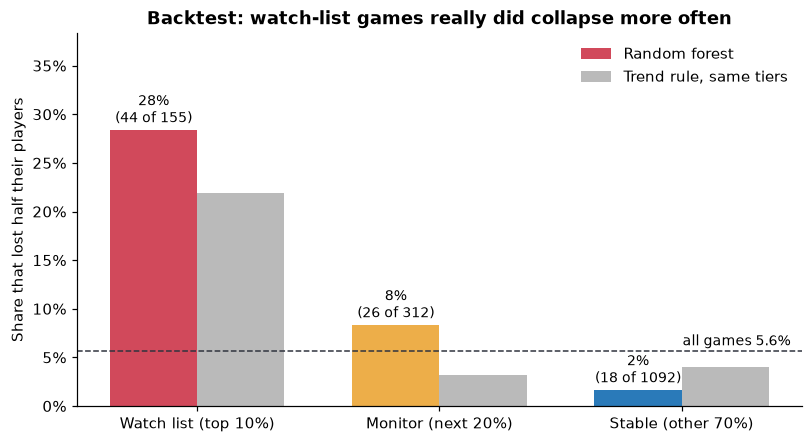

In [17]:
TIER_LABELS = ["Watch list (top 10%)", "Monitor (next 20%)", "Stable (other 70%)"]


def assign_tiers(scores):
    rank = pd.Series(scores).rank(ascending=False, method="first") / len(scores)
    return pd.cut(rank, [0, 0.1, 0.3, 1.0], labels=TIER_LABELS).to_numpy()


backtest = test[["name", "publisher", "early_mean", "future_mean", "change_ratio", "declined", "size_band"]].copy()
backtest["decline_score"] = test_scores[best_name]
backtest["tier"] = pd.Categorical(assign_tiers(backtest["decline_score"].to_numpy()), categories=TIER_LABELS)
tier_summary = backtest.groupby("tier", observed=False).agg(
    games=("name", "size"), lost_half=("declined", "sum"), share_lost_half=("declined", "mean"),
    median_change=("change_ratio", "median"), median_players_now=("early_mean", "median"))
tier_summary["share_of_all_declines"] = tier_summary["lost_half"] / backtest["declined"].sum()
trend_tiers = pd.Categorical(assign_tiers(test_scores["Trend rule"]), categories=TIER_LABELS)
tier_summary["trend_rule_share_lost_half"] = backtest.groupby(trend_tiers, observed=False)["declined"].mean()
display(tier_summary.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = np.arange(len(tier_summary))
ax.bar(x - 0.18, tier_summary["share_lost_half"], width=0.36, color=[COLORS["decline"], COLORS["accent"], COLORS["stable"]],
       label=f"{best_name}")
ax.bar(x + 0.18, tier_summary["trend_rule_share_lost_half"], width=0.36, color=COLORS["neutral"], alpha=0.6, label="Trend rule, same tiers")
for xi, (share, lost, games) in enumerate(zip(tier_summary["share_lost_half"], tier_summary["lost_half"], tier_summary["games"])):
    ax.text(xi - 0.18, share + 0.008, f"{share:.0%}\n({lost} of {games})", ha="center", fontsize=9)
ax.axhline(y_test.mean(), color=COLORS["dark"], ls="--", lw=1)
ax.text(2.45, y_test.mean() + 0.006, f"all games {y_test.mean():.1%}", ha="right", fontsize=9)
ax.set_xticks(x, tier_summary.index)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, tier_summary["share_lost_half"].max() * 1.35)
ax.set(ylabel="Share that lost half their players", title="Backtest: watch-list games really did collapse more often")
ax.legend(frameon=False, loc="upper right")
save(fig, "fig08_watchlist_backtest")
plt.show()

The tiers are sharp:

| Tier | Lost half | Share of all collapses |
|---|---:|---:|
| Watch list | 28% | 50% |
| Monitor | 8% | 30% |
| Stable | 1.6% | 20% |

A publisher reviewing only the 10% watch list would see half of next year's collapses. Watch list plus monitor tier (30% of the catalogue) covers 80%.

Big games (1,000+ players) in the test: 170, of which 11 lost half; 5 on the watch list, 3 of them lost half


,name,early_mean,future_mean,change_ratio,decline_score
appid,,,,,
361420,ASTRONEER,3898.03,1860.37,0.48,0.70
264710,Subnautica,4003.69,2226.01,0.56,0.62
365590,Tom Clancy's The Division,4097.99,644.90,0.16,0.52
433850,H1Z1,2384.35,717.89,0.30,0.42
489520,Minion Masters,1000.08,1468.21,1.47,0.40


Saved reports/figures/decline/fig09_examples.png


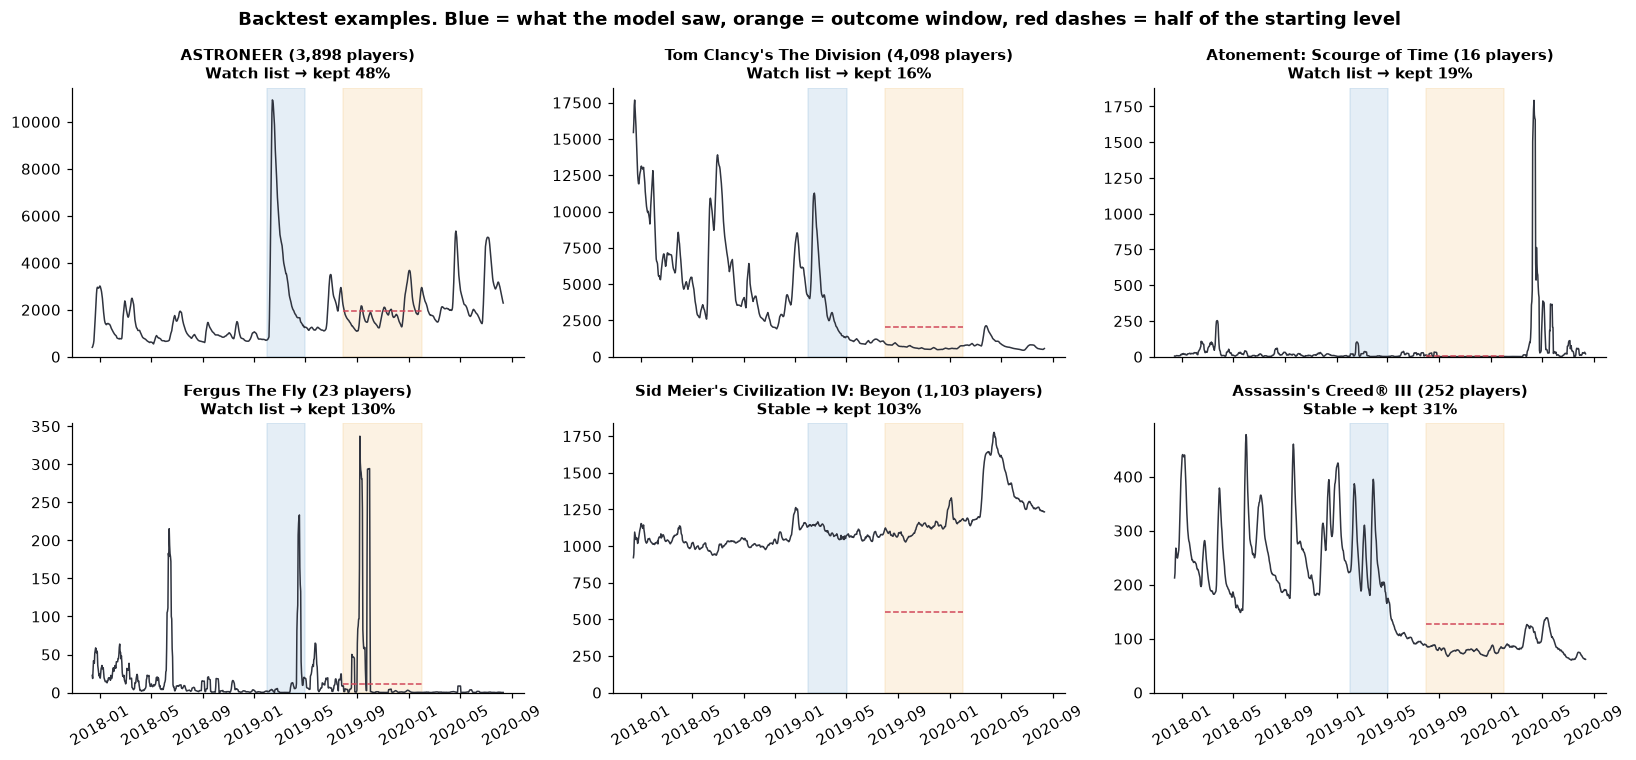

In [18]:
big = backtest[backtest["early_mean"] >= 1000]
big_flagged = big[big["tier"] == TIER_LABELS[0]].sort_values("decline_score", ascending=False)
print(f"Big games (1,000+ players) in the test: {len(big)}, of which {big['declined'].sum()} lost half; "
      f"{len(big_flagged)} on the watch list, {big_flagged['declined'].sum()} of them lost half")
display(big_flagged[["name", "early_mean", "future_mean", "change_ratio", "decline_score"]].round(2))

examples = pd.concat([
    big[(big["tier"] == TIER_LABELS[0]) & (big["declined"] == 1)].nlargest(2, "decline_score"),
    backtest[(backtest["tier"] == TIER_LABELS[0]) & (backtest["declined"] == 1) & (backtest["early_mean"] < 1000)].nlargest(1, "decline_score"),
    backtest[(backtest["tier"] == TIER_LABELS[0]) & (backtest["declined"] == 0)].nlargest(1, "decline_score"),
    big[(big["tier"] == TIER_LABELS[2]) & (big["declined"] == 0)].nsmallest(1, "decline_score"),
    backtest[(backtest["tier"] == TIER_LABELS[2]) & (backtest["declined"] == 1)].nsmallest(1, "decline_score"),
])
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
origin = ORIGINS["test"]
for ax, (appid, row) in zip(axes.ravel(), examples.iterrows()):
    history = panel[panel["appid"] == appid].set_index("date")["mean_player_count"].rolling(7, min_periods=1).mean()
    ax.plot(history.index, history, color=COLORS["dark"], lw=1)
    ax.axvspan(origin, origin + pd.Timedelta(days=FEATURE_DAYS), color=COLORS["stable"], alpha=0.12)
    ax.axvspan(origin + pd.Timedelta(days=TARGET_START), origin + pd.Timedelta(days=TARGET_END), color=COLORS["accent"], alpha=0.15)
    ax.hlines(row["early_mean"] * DECLINE_RATIO, origin + pd.Timedelta(days=TARGET_START), origin + pd.Timedelta(days=TARGET_END),
              color=COLORS["decline"], ls="--", lw=1)
    outcome = f"kept {row['change_ratio']:.0%}"
    ax.set_title(f"{row['name'][:34]} ({row['early_mean']:,.0f} players)\n{row['tier'].split(' (')[0]} → {outcome}", fontsize=10)
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", labelrotation=30)
fig.suptitle("Backtest examples. Blue = what the model saw, orange = outcome window, red dashes = half of the starting level",
             fontweight="bold")
fig.tight_layout()
save(fig, "fig09_examples")
plt.show()

### 9b. Forward watch list from the last 90 days of data

The deployable model is trained on all four labelled starts and scores every live game on 15 May – 12 Aug 2020. This predicts Nov 2020 – Aug 2021. Those outcomes are outside the data, so this is a forecast. Because the 2020 lockdown inflated player counts in the scoring window, the absolute probabilities are less meaningful than the ranking.

In [19]:
forecast_origin = DATA_END - pd.Timedelta(days=FEATURE_DAYS - 1)
latest = build_dataset(shared(forecast_origin), labelled=False)
all_labelled = pd.concat(datasets.values())
final_model = clone(make_model(best_name)).fit(all_labelled[ALL_FEATURES], all_labelled["declined"])
forecast = latest[["name", "publisher", "early_mean", "trend_log_per_30d"]].rename(
    columns={"early_mean": "mean_players_last_90_days", "trend_log_per_30d": "trend_log_per_30_days"})
forecast["decline_score"] = final_model.predict_proba(latest[ALL_FEATURES])[:, 1]
forecast["tier"] = assign_tiers(forecast["decline_score"].to_numpy())
forecast = forecast.sort_values("decline_score", ascending=False)
print(f"Forecast start {forecast_origin.date()}: {len(forecast):,} live games scored")
display(forecast.head(10).round(3))

backtest.sort_values("decline_score", ascending=False).round(4).to_csv(REPORT_DIR / "decline_watchlist_backtest_2019.csv", index_label="appid")
forecast.round(4).to_csv(REPORT_DIR / "decline_watchlist_forecast_2020-08.csv", index_label="appid")
print("Wrote reports/decline_watchlist_backtest_2019.csv and reports/decline_watchlist_forecast_2020-08.csv")

Forecast start 2020-05-15: 1,554 live games scored


,name,publisher,mean_players_last_90_days,trend_log_per_30_days,decline_score,tier
appid,,,,,,
619730,Mad Driver,NaN,11.005,-1.222,0.971,Watch list (top 10%)
633880,Lone Warrior,EHTechnology,11.846,-1.248,0.969,Watch list (top 10%)
616360,Crimson Earth,EHTechnology,27.483,-1.420,0.969,Watch list (top 10%)
631530,Fight or Die 2,Vyacheslav Shilikhin,30.736,-1.517,0.964,Watch list (top 10%)
619520,Destruction 48,Vyacheslav Shilikhin,27.794,-1.445,0.963,Watch list (top 10%)
582430,Jumping Tank,Maximus.ez,34.507,-1.588,0.962,Watch list (top 10%)
596690,REVENGE: First Blood,Vyacheslav Shilikhin,18.080,-1.421,0.960,Watch list (top 10%)
608560,Last Tale,YarGri,17.331,-1.381,0.959,Watch list (top 10%)
625950,Pic Guesser,Lestyo,11.334,-1.274,0.953,Watch list (top 10%)


Wrote reports/decline_watchlist_backtest_2019.csv and reports/decline_watchlist_forecast_2020-08.csv


## 10. Save metrics

In [20]:
def frame_dict(frame):
    return json.loads(frame.round(4).to_json(orient="index"))


results = {
    "settings": {"feature_days": FEATURE_DAYS, "target_days": [TARGET_START, TARGET_END], "min_players": MIN_PLAYERS,
                 "decline_ratio": DECLINE_RATIO, "watchlist_share": WATCHLIST_SHARE, "trend_rule_cutoff": round(TREND_CUTOFF, 4),
                 "origins": {k: str(v.date()) for k, v in ORIGINS.items()}, "best_model": best_name},
    "overview": json.loads(overview.astype({"decline_rate": float, "median_change": float, "lost_25pct_or_more": float}).round(4).to_json(orient="index", default_handler=str)),
    "groups": {k: v.round(4).to_dict(orient="records") for k, v in groups.items()},
    "cv": {m: {k: round(cv_results.loc[m, (k, "mean")], 4) for k in ["roc_auc", "watchlist_precision", "watchlist_lift", "balanced_accuracy"]}
           for m in cv_results.index},
    "test": frame_dict(test_results),
    "by_size": size_results.round(4).to_dict(orient="records"),
    "launch": {"games": len(launch), "declines": int(y_launch.sum()), "kinds": launch["launch_kind"].value_counts().to_dict(),
               "results": frame_dict(launch_results),
               "decline_rate_by_score_third": launch.groupby(launch_risk, observed=False)["declined"].mean().round(4).to_dict()},
    "ablation": frame_dict(ablation),
    "twitch_auc_change": [round(v, 4) for v in twitch_delta],
    "group_importance": frame_dict(group_importance),
    "top_features": frame_dict(single_importance.head(10)),
    "sensitivity": frame_dict(sensitivity),
    "covid_test": {"games": len(covid), "declines": int(y_covid.sum()), "results": frame_dict(covid_results)},
    "regression": frame_dict(regression_results),
    "tiers_backtest": json.loads(tier_summary.round(4).to_json(orient="index")),
    "big_games": {"games": len(big), "declines": int(big["declined"].sum()), "on_watchlist": len(big_flagged),
                  "on_watchlist_declined": int(big_flagged["declined"].sum())},
    "forecast_games": len(forecast),
}
(REPORT_DIR / "decline_metrics.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Wrote reports/decline_metrics.json")

Wrote reports/decline_metrics.json


## 11. Conclusions

1. **A relative decline is predictable, and not from simple rules.** Out-of-time ROC-AUC is 0.826, against 0.59 for trend extrapolation and 0.61 for game age. The top-10% watch list catches half of all collapses at 5× the base rate, and the result held in the 2020 lockdown period (AUC 0.826, 5.9× lift).
2. **It works for big games**, unlike the 10-player floor model. AUC is 0.80 for games with 1,000+ players, and three of the five big games on the 2019 watch list lost half (The Division kept 16%).
3. **Launch-stage games: helpful but not yet better than a trend rule** (AUC 0.787 vs 0.774 on 141 launches). The highest-scored third of launches lost half 79% of the time, the lowest third 23%.
4. **Twitch adds nothing** once Steam activity is known. Stability (volatility), trend and age drive the prediction.
5. **Rank, do not threshold.** Market-wide decline rates swing from 20% to 3% between periods, so probabilities do not transfer, but rankings do. The product is a ranked watch list, refreshed each quarter.

The full write-up is in [`reports/technical_report.md`](../reports/technical_report.md).